# Figure 3d. STRING protein-protein interaction enrichment of trans gene pairs

Fold enrichment of high-confidence STRING v12 interactions (combined score ≥ 500) among gene pairs linked by the same colocalized locus: within-trans pairs (two trans target genes of the same locus) and cis-trans pairs (the cis-eGene and a trans target gene), shown separately for trans-eGene and trans-eProgram loci. Fold enrichment = observed number of PPI pairs / mean number in 100 permutations in which the second gene of each pair is replaced by a random protein-coding gene. Error bars are ± 1 SE, with SE = (permutation SD / permutation mean) × fold enrichment. Red asterisks mark empirical permutation P < 0.05 (P = (#perm ≥ observed + 1) / 101, so the smallest attainable P is 0.0099); P values are not corrected for multiple testing.

Input: `data/Figure_3d_string_ppi.rds`

In [1]:
library(ggplot2)
ppi <- readRDS("data/Figure_3d_string_ppi.rds")
ppi

trans_method,category,observed,n_pairs,perm_mean,perm_sd,fold_enrichment,fe_se,perm_p,significant
<chr>,<fct>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
eGene,cis-trans pairs,48,17012,52.61,7.120741,0.9123741,0.12348944,0.71287129,FALSE
eGene,within-trans pairs,1026,217708,679.04,24.276155,1.5109566,0.05401776,0.00990099,TRUE
eProgram,cis-trans pairs,1500,461425,1361.04,37.693854,1.1020984,0.03052249,0.00990099,TRUE
eProgram,within-trans pairs,61500,11033879,33029.44,181.328226,1.8619753,0.01022205,0.00990099,TRUE


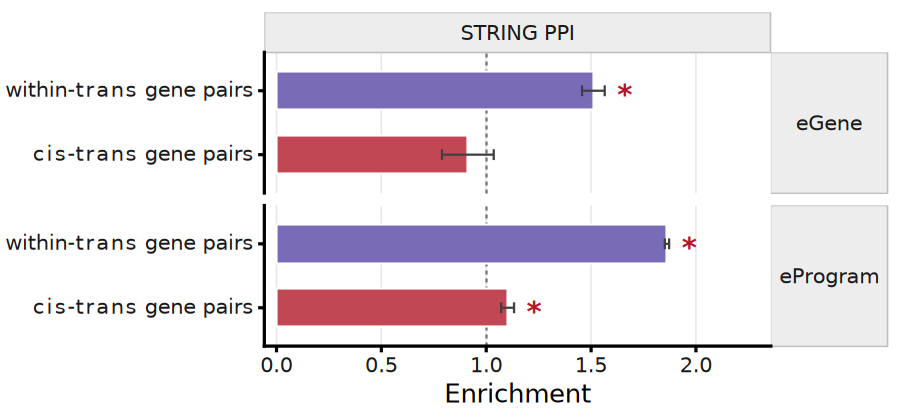

In [2]:
ppi$category     <- factor(ppi$category, levels = c("cis-trans pairs", "within-trans pairs"))
ppi$trans_method <- factor(ppi$trans_method, levels = c("eGene", "eProgram"))
ppi$ci_low  <- ppi$fold_enrichment - ppi$fe_se
ppi$ci_high <- ppi$fold_enrichment + ppi$fe_se
ppi$star    <- ifelse(ppi$significant, "*", "")
ppi$panel   <- "STRING PPI"

ppi_colors <- c("cis-trans pairs" = "#C24755", "within-trans pairs" = "#7A6BB7")
ppi_labels <- c("cis-trans pairs"    = "italic(cis)*'-'*italic(trans)*' gene pairs'",
                "within-trans pairs" = "'within-'*italic(trans)*' gene pairs'")

p <- ggplot(ppi, aes(y = category, x = fold_enrichment, fill = category)) +
  geom_vline(xintercept = 1, linetype = "dashed", colour = "grey45", linewidth = 0.48) +
  geom_col(width = 0.60, colour = "white", linewidth = 0.45) +
  geom_errorbar(aes(xmin = ci_low, xmax = ci_high), orientation = "y",
                width = 0.17, linewidth = 0.48, colour = "grey25") +
  geom_text(aes(x = ci_high + 0.06, label = star), hjust = 0, vjust = 0.65,
            size = 6, colour = "#B2182B", fontface = "bold") +
  facet_grid(rows = vars(trans_method), cols = vars(panel)) +
  scale_y_discrete(labels = function(x) parse(text = ppi_labels[x])) +
  scale_fill_manual(values = ppi_colors, guide = "none") +
  scale_x_continuous(expand = expansion(mult = c(0.03, 0.22))) +
  labs(x = "Enrichment", y = NULL) +
  theme_classic(base_size = 15) +
  theme(axis.text = element_text(colour = "grey10"),
        panel.grid.major.x = element_line(colour = "grey91", linewidth = 0.35),
        strip.background = element_rect(fill = "grey93", colour = "grey75", linewidth = 0.35),
        strip.text.y.right = element_text(angle = 0))

options(repr.plot.width = 7.5, repr.plot.height = 3.5)
p